# Deduplicação de bug reports com LLM — pipeline completo (Google Colab)

Simula o fluxo de um gestor de issues (tipo Jira/Bugzilla): a base começa com issues conhecidas e, a cada **nova issue** que chega, o sistema (1) busca candidatas parecidas no histórico, (2) pede a uma LLM para julgar se é duplicata, (3) decide e (4) **insere a issue na base**.

**Arquitetura: recuperar + julgar (retrieve-and-rerank com LLM como juiz)**

| Etapa | O que faz | Escolha |
|---|---|---|
| Amostragem | a partir do CSV completo, gera a **base (1000 issues, 50% duplicadas)** e **100 issues diferentes para teste (50% duplicadas)**, lendo só o necessário (2 passadas) | dentro deste notebook |
| Pré-processamento | usa só o relato original (corta comentários posteriores, que vazam o rótulo, ex.: "this bug is a duplicate of 415"); remove cabeçalho, e-mails, telefones, IPs, endereços hex e separadores ASCII; tokeniza camelCase/snake_case | regex |
| Recuperação híbrida | BM25 (léxico, incremental) + embeddings densos, fundidos por RRF → top-K candidatas | `BAAI/bge-base-en-v1.5` |
| Juiz LLM | para cada candidata, pergunta "A e B são duplicatas?" e lê P(Yes) direto dos *logits* (1 passada, sem gerar texto) | `Qwen/Qwen3-8B` em 4-bit (cabe na T4 grátis) |
| Decisão | duplicata se a maior P(Yes) ≥ limiar (calibrado em issues da própria base, nunca nas de teste) | limiar |
| Inserção | a issue entra na base com o resultado (`duplicate_of`) | — |

**Comparação sem LLM (seção 9):** os mesmos 100 casos de teste são decididos também por baselines puramente sintático (BM25), semântico (embeddings) e híbrido linear, com limiares calibrados na base da mesma forma, para medir quanto o juiz LLM acrescenta.

**Resultados salvos:** com `SALVAR_NO_DRIVE = True` o notebook monta o seu Google Drive (pede autorização na 1ª vez) e grava em `MyDrive/dedup_bugs/`: o cache do juiz e o CSV original na raiz (compartilhados entre sessões, o que permite retomar se o Colab cair) e, em `execucoes/<data_hora>/`, a amostra, os resultados, as matrizes, os erros e o `metricas.json` de cada execução. Com `False` (ou sem Drive) grava em `/content/saida`, que o Colab apaga ao fim da sessão.

**Por que esse LLM:** Apache-2.0, sem *gate* (não precisa de token do Hugging Face), arquitetura Transformer padrão (carrega com `transformers` + `bitsandbytes` sem *kernels* especiais) e ~6 GB de VRAM em 4-bit, sobrando folga na T4 de 15 GB do Colab gratuito. Para trocar, mude `LLM_MODEL` na célula de configuração.

**Protocolo de avaliação:** a base inicial tem **1000 issues** (500 duplicadas / 500 não); o teste usa **100 outras issues** do dataset original, que não estão na base (50 duplicadas / 50 não). Elas são submetidas uma a uma, em ordem cronológica, como issues novas: comparadas com a base e inseridas nela — ao final a base tem 1100. A original de cada duplicata de teste pode estar **na base ou no próprio teste** (`FRAC_ORIG_TESTE`); no segundo caso ela é uma das não duplicadas do teste e chega antes da duplicata.

> Runtime → Alterar tipo de ambiente de execução → **GPU (T4)**.

In [ ]:
# Dependências (o Colab já traz torch/pandas/scikit-learn/transformers)
!pip install -q -U "bitsandbytes>=0.46.1" "transformers>=4.51" accelerate sentence-transformers

## 1. Configuração

In [ ]:
import os, re, json, html, time, random
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# --- onde salvar os resultados ---
SALVAR_NO_DRIVE = True                      # True: grava no seu Google Drive (sobrevive ao fim da sessão do Colab)
PASTA_DRIVE = "MyDrive/dedup_bugs"          # pasta dentro do Drive (criada se não existir)
OUT_DIR = "/content/saida"                  # usada se o Drive estiver desligado ou indisponível (apagada ao fim da sessão)
if SALVAR_NO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")       # na 1ª vez abre uma janela pedindo autorização
        OUT_DIR = f"/content/drive/{PASTA_DRIVE}"
    except Exception as e:
        print(f"Drive indisponível ({type(e).__name__}); salvando em {OUT_DIR}")
RUN_DIR = f"{OUT_DIR}/execucoes/{time.strftime('%Y%m%d_%H%M%S')}"      # resultados desta execução
os.makedirs(RUN_DIR, exist_ok=True)
print("cache do juiz e CSV original ficam em:", OUT_DIR)
print("resultados desta execução em:", RUN_DIR)

# --- dados ---
CSV_ORIGINAL = "/content/mozilla_core.csv"     # CSV completo; se não estiver aqui, o notebook procura em OUT_DIR ou pede o upload
CSV_AMOSTRA  = f"{RUN_DIR}/amostra_1100.csv"   # base (1000) + teste (100), gerado na seção 2
N_BASE, N_EVAL = 10000, 1000      # base de 1000 issues + 100 issues DIFERENTES para teste (ambos 50/50)
FRAC_ORIG_TESTE = 0.5             # fração das duplicatas de teste cuja ORIGINAL também está no conjunto de teste
                                  # (0 = todas as originais na base; 1 = todas no teste; 0.5 = metade/metade)

# --- modelos (todos gratuitos / open-weight) ---
EMB_MODEL = "BAAI/bge-base-en-v1.5"
LLM_MODEL = "Qwen/Qwen3-8B"                    # alternativa mais leve: "Qwen/Qwen3-4B-Instruct-2507"

# --- recuperação e decisão ---
TOP_K = 5            # candidatas enviadas ao juiz
POOL = 50            # profundidade de cada ranking antes da fusão
RRF_K = 60           # constante do Reciprocal Rank Fusion
THRESHOLD = 0.5      # limiar de P(Yes) (substituído pelo calibrado se CALIBRAR=True)
CALIBRAR = True      # calibra o limiar em issues da BASE (não usa as de avaliação)
N_CAL = 60           # nº de issues da base usadas na calibração (metade duplicadas)

# --- texto ---
MAX_CHARS_EMB = 2000
MAX_CHARS_LLM = 900
JUDGE_BS = 4         # pares por lote no juiz (reduza se faltar memória)

PROMPT_VERSION = "v1"
CACHE_PATH = f"{OUT_DIR}/cache_juiz_{LLM_MODEL.split('/')[-1]}_{PROMPT_VERSION}.jsonl"  # raiz de OUT_DIR: compartilhado entre execuções, permite retomar

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cache do juiz e CSV original ficam em: /content/drive/MyDrive/dedup_bugs
resultados desta execução em: /content/drive/MyDrive/dedup_bugs/execucoes/20261119_123443


## 2. Amostragem do dataset original

Gera `amostra_1100.csv` com a coluna `split`: **`base`** = 1000 issues (500 duplicadas + 500 não) e **`eval`** = 100 issues diferentes das da base (50 duplicadas + 50 não).

**Onde fica a original de cada duplicata de teste** (controlado por `FRAC_ORIG_TESTE`):
- **na base** (`orig_local = "base"`): a original foi sorteada para a base e a duplicata de teste é uma duplicata *a mais* desse cluster (no máximo uma por cluster);
- **no próprio teste** (`orig_local = "teste"`): a original é uma das não duplicadas do teste e chega **antes** da duplicata (só são sorteados pares em que a original foi criada primeiro, senão a duplicata chegaria sem a original no sistema). Esses clusters não têm nenhuma issue na base.

As demais não duplicadas de teste são issues **isoladas** (nenhuma outra issue do dataset inteiro aponta para elas), então não há "duplicata oculta". Toda duplicada da base tem a sua original na base.

Para o CSV completo (centenas de milhares de issues com descrições longas) ser leve, a leitura é feita em **duas passadas**: primeiro só `Issue_id`, `Duplicated_issue`, `Resolution`, `Title` e `Created_time` para escolher as issues; depois, em blocos, só as linhas escolhidas com todas as colunas.


In [ ]:

# O CSV completo pode estar em /content, na pasta do Drive (OUT_DIR) ou ser enviado agora.
# Dica: guarde mozilla_core.csv em OUT_DIR para não precisar reenviar a cada sessão.
if not os.path.exists(CSV_ORIGINAL):
    alt = os.path.join(OUT_DIR, "mozilla_core.csv")
    if os.path.exists(alt):
        CSV_ORIGINAL = alt
    else:
        from google.colab import files
        up = files.upload()
        os.rename(list(up)[0], CSV_ORIGINAL)
print("CSV original:", CSV_ORIGINAL)


CSV original: /content/mozilla_core.csv


In [ ]:
def resolver_raiz(dup_map, i, max_hops=20):
    """Segue a cadeia duplicada -> mestre -> ... até a raiz (issue que não é duplicada)."""
    atual, vistos = i, {i}
    for _ in range(max_hops):
        prox = dup_map.get(atual)
        if prox is None:
            return atual if atual != i else None
        if prox in vistos:            # ciclo
            return None
        vistos.add(prox); atual = prox
    return None


def selecionar_issues(path, n_base=1000, n_eval=100, frac_mestres=0.6, frac_orig_teste=0.5, seed=42):
    """1ª passada: lê só colunas leves e devolve {issue_id: (is_duplicate, master_id, split, orig_local)}.
    BASE = n_base issues (50% duplicadas); TESTE = n_eval issues DIFERENTES das da base (50% duplicadas).
    A original de cada duplicata de teste fica na base ou no próprio teste (fração `frac_orig_teste`)."""
    rng = np.random.default_rng(seed)
    n_dup, n_nao = n_base // 2, n_base - n_base // 2          # base
    e_dup, e_nao = n_eval // 2, n_eval - n_eval // 2          # teste
    e_dup_t = int(round(e_dup * frac_orig_teste))             # duplicatas de teste com a original NO TESTE
    e_dup_b = e_dup - e_dup_t                                 # duplicatas de teste com a original NA BASE
    assert 0 <= e_dup_t <= e_nao, "frac_orig_teste incompatível com o nº de não duplicadas do teste"

    meta = pd.read_csv(path, usecols=["Issue_id", "Duplicated_issue", "Resolution", "Title", "Created_time"], low_memory=False)
    meta["Issue_id"] = pd.to_numeric(meta["Issue_id"], errors="coerce")
    meta["Duplicated_issue"] = pd.to_numeric(meta["Duplicated_issue"], errors="coerce")
    meta = meta.dropna(subset=["Issue_id", "Title"]).drop_duplicates("Issue_id")
    print(f"dataset original: {len(meta):,} issues | com Duplicated_issue: {meta.Duplicated_issue.notna().sum():,}")

    ids = set(meta.Issue_id.astype(int))
    criada = dict(zip(meta.Issue_id.astype(int), pd.to_datetime(meta.Created_time, utc=True, errors="coerce")))
    dup_map = {int(i): int(m) for i, m in zip(meta.Issue_id, meta.Duplicated_issue) if pd.notna(m)}
    referenciadas = set(dup_map.values())
    marcada_dup = set(meta.Issue_id[meta.Resolution.fillna("").str.upper().eq("DUPLICATE")].astype(int))

    clusters = {}                      # raiz -> duplicadas válidas (raiz existe no dataset e não é duplicada)
    for i in dup_map:
        raiz = resolver_raiz(dup_map, i)
        if raiz is not None and raiz in ids and raiz not in dup_map:
            clusters.setdefault(raiz, []).append(i)
    isoladas = [i for i in ids if i not in dup_map and i not in marcada_dup and i not in referenciadas]

    n_mestres = int(round(n_nao * frac_mestres)); n_iso = n_nao - n_mestres
    n_iso_teste = e_nao - e_dup_t                              # isoladas no teste (o resto são as originais do teste)
    raizes = sorted(clusters)
    assert len(raizes) >= n_mestres + e_dup_t, f"poucos clusters ({len(raizes)}) para {n_mestres} mestres + {e_dup_t} originais de teste"
    assert sum(map(len, clusters.values())) >= n_dup + e_dup, "poucas duplicadas no dataset"
    assert len(isoladas) >= n_iso + n_iso_teste, "poucas issues isoladas"

    # --- BASE: escolhe mestres (trocando clusters pequenos por grandes se faltar capacidade) e distribui as duplicadas ---
    raizes = [raizes[k] for k in rng.permutation(len(raizes))]
    escolhidas, resto = raizes[:n_mestres], raizes[n_mestres:]
    cap = lambda r: len(clusters[r])
    alvo = n_dup + e_dup_b             # capacidade para a base E para as duplicatas de teste com original na base
    capacidade = sum(map(cap, escolhidas))
    if capacidade < alvo:
        resto.sort(key=cap, reverse=True); escolhidas.sort(key=cap)
        for k in range(min(len(escolhidas), len(resto))):
            if capacidade >= alvo: break
            if cap(resto[k]) > cap(escolhidas[k]):
                capacidade += cap(resto[k]) - cap(escolhidas[k])
                escolhidas[k], resto[k] = resto[k], escolhidas[k]
        assert capacidade >= alvo, "clusters insuficientes: diminua frac_mestres"
    sel = {r: [int(rng.choice(clusters[r]))] for r in escolhidas}
    total = len(escolhidas)
    while total < n_dup:
        for k in rng.permutation(len(escolhidas)):
            r = escolhidas[k]
            extra = [x for x in clusters[r] if x not in sel[r]]
            if len(extra) > 1 and total < n_dup:        # deixa >=1 sobrando por cluster para o teste
                sel[r].append(int(rng.choice(extra))); total += 1
        if total < n_dup and all(len([x for x in clusters[r] if x not in sel[r]]) <= 1 for r in escolhidas):
            break
    if total < n_dup:                                  # sem folga: usa também as sobras
        for r in escolhidas:
            for x in clusters[r]:
                if total < n_dup and x not in sel[r]:
                    sel[r].append(x); total += 1
    assert total == n_dup, "não foi possível completar as duplicadas da base"

    # --- TESTE (a): duplicata NOVA (fora da base) de e_dup_b clusters cuja original está na base ---
    com_sobra = [r for r in escolhidas if any(x not in sel[r] for x in clusters[r])]
    assert len(com_sobra) >= e_dup_b, f"só {len(com_sobra)} clusters com duplicata sobrando; aumente frac_mestres"
    teste_dup_base = {}
    for k in rng.permutation(len(com_sobra))[:e_dup_b]:
        r = com_sobra[k]
        teste_dup_base[int(rng.choice([x for x in clusters[r] if x not in sel[r]]))] = r

    # --- TESTE (b): original E duplicata no teste, em clusters sem nenhuma issue na base.
    #     Só pares em que a original foi criada ANTES da duplicata (ela precisa chegar primeiro). ---
    pares_ok = {}
    for r in resto:
        tr = criada.get(r)
        ds = [x for x in clusters[r] if pd.notna(tr) and pd.notna(criada.get(x)) and criada[x] > tr]
        if ds:
            pares_ok[r] = ds
    assert len(pares_ok) >= e_dup_t, (f"só {len(pares_ok)} clusters fora da base com a original criada antes da duplicata; "
                                      "reduza frac_orig_teste")
    cand_r = sorted(pares_ok)
    teste_orig, teste_dup_teste = [], {}
    for k in rng.permutation(len(cand_r))[:e_dup_t]:
        r = cand_r[k]
        teste_orig.append(r)
        teste_dup_teste[int(rng.choice(pares_ok[r]))] = r

    # isoladas: n_iso para a base e n_iso_teste DIFERENTES para o teste
    iso = [int(isoladas[k]) for k in rng.permutation(len(isoladas))[: n_iso + n_iso_teste]]
    iso_base, iso_teste = iso[:n_iso], iso[n_iso:]

    papel = {}
    for r, ds in sel.items():
        papel[r] = (0, r, "base", "-")
        for d in ds:
            papel[d] = (1, r, "base", "base")
    for i in iso_base:
        papel[i] = (0, i, "base", "-")
    for d, r in teste_dup_base.items():
        papel[d] = (1, r, "eval", "base")
    for r in teste_orig:
        papel[r] = (0, r, "eval", "-")                 # a original, no teste, é uma não duplicada
    for d, r in teste_dup_teste.items():
        papel[d] = (1, r, "eval", "teste")
    for i in iso_teste:
        papel[i] = (0, i, "eval", "-")
    return papel


def gerar_amostra(path, saida, **kw):
    papel = selecionar_issues(path, **kw)
    partes = []                        # 2ª passada: só as linhas escolhidas, com todas as colunas
    for ch in pd.read_csv(path, chunksize=50_000, low_memory=False):
        ch["Issue_id"] = pd.to_numeric(ch["Issue_id"], errors="coerce")
        partes.append(ch[ch.Issue_id.isin(papel)])
    am = pd.concat(partes).drop_duplicates("Issue_id")
    am["Issue_id"] = am["Issue_id"].astype(int)
    am["Description"] = am["Description"].fillna("")
    am["is_duplicate"] = am.Issue_id.map(lambda i: papel[i][0])
    am["master_id"] = am.Issue_id.map(lambda i: papel[i][1])
    am["split"] = am.Issue_id.map(lambda i: papel[i][2])
    am["orig_local"] = am.Issue_id.map(lambda i: papel[i][3])   # onde está a original da duplicata: base | teste | "-"
    am = am.sort_values("Created_time", key=lambda c: pd.to_datetime(c, utc=True, errors="coerce"), kind="stable").reset_index(drop=True)
    am.to_csv(saida, index=False)
    print(f"amostra salva em {saida}: {len(am)} issues")
    print(am.groupby(["split", "is_duplicate"]).size().unstack(fill_value=0).rename(columns={0: "não duplicada", 1: "duplicada"}))
    print("duplicatas de teste por local da original:", am[(am.split == "eval") & (am.is_duplicate == 1)].orig_local.value_counts().to_dict())
    return am

amostra = gerar_amostra(CSV_ORIGINAL, CSV_AMOSTRA, n_base=N_BASE, n_eval=N_EVAL, frac_orig_teste=FRAC_ORIG_TESTE, seed=SEED)

dataset original: 205,069 issues | com Duplicated_issue: 44,691
amostra salva em /content/drive/MyDrive/dedup_bugs/execucoes/20261119_123443/amostra_1100.csv: 11000 issues
is_duplicate  não duplicada  duplicada
split                                 
base                   5000       5000
eval                    500        500
duplicatas de teste por local da original: {'teste': 250, 'base': 250}


## 3. Pré-processamento do texto

- **Só o relato original.** O texto do dataset concatena o relato com os comentários posteriores (`Updated by ...`), onde aparece "this bug is a duplicate of N". Manter isso vazaria o rótulo; além disso, uma issue que acabou de chegar ao tracker ainda não tem comentários, então cortar também é fiel ao uso real.
- **Ruído removido:** cabeçalho `Created by ... Additional Details :`, e-mails (inclusive `user=dominio@host`), telefones, IPs, endereços hexadecimais de *stack traces*, linhas decorativas (`-----`, `=====`).
- **Mantidas:** URLs, nomes de funções/arquivos, mensagens de erro — são justamente o que liga duas duplicatas.
- **Tokenização para BM25:** além do token inteiro, `nsIWebBrowser` → `ns`, `web`, `browser` e `LOCAL_MACHINE` → `local`, `machine`; o título pesa o dobro.

In [ ]:
_RE_UPD     = re.compile(r"\s*;?\s*Updated by [^;()]*(?:\([^)]*\))?\s*on\s", re.I)       # início dos comentários posteriores
_RE_HEADER  = re.compile(r"^\s*Created by .*?\d{1,2}:\d{2}:\d{2}\s*[AP]M\s*\w*\s*;?\s*(?:Additional Details\s*:\s*;?)?", re.I | re.S)
_RE_HEADER2 = re.compile(r"^\s*Created by\b.{0,250}?Additional Details\s*:\s*;?", re.I | re.S)   # cabeçalho fora do padrão
_RE_ADDL    = re.compile(r"Additional Details\s*:\s*;?", re.I)
_RE_EMAIL   = re.compile(r"[\w.+=-]+\s?@\s?[\w-]+(?:\.[\w-]+)+")
_RE_PHONE   = re.compile(r"\(?\b\d{3}\)?[-. ]\d{3}[-. ]\d{4}(?:\s?x\d+)?\b")
_RE_IP      = re.compile(r"\b\d{1,3}(?:\.\d{1,3}){3}\b")
_RE_HEX     = re.compile(r"\b0x[0-9a-f]{4,}\b|\b(?=[0-9a-f]*\d)[0-9a-f]{8,}\b", re.I)
_RE_RULE    = re.compile(r"[-=_*#~+]{3,}")
_RE_LEAK    = re.compile(r"(?i)\b(?:this\s+(?:bug|issue)\s+is\s+)?(?:a\s+)?(?:duplicate|dup|dupe)s?\s+of\b[^;.\n]{0,60}")

def limpar_descricao(desc):
    """Mantém só o relato original, sem cabeçalho, contatos, endereços de memória e vazamento do rótulo."""
    if not isinstance(desc, str):
        return ""
    t = html.unescape(desc)
    t = _RE_UPD.split(t, maxsplit=1)[0]
    t = _RE_HEADER.sub("", t, count=1)
    if t.lstrip().lower().startswith("created by"):
        t = _RE_HEADER2.sub("", t, count=1)
    t = _RE_ADDL.sub(" ", t)
    for rx in (_RE_LEAK, _RE_EMAIL, _RE_PHONE, _RE_IP, _RE_HEX, _RE_RULE):
        t = rx.sub(" ", t)
    t = re.sub(r"(;\s*){2,}", "; ", t)
    return re.sub(r"\s+", " ", t).strip(" ;")

STOP = set("a an the and or of to in on at is are was were be been it this that for with as by from not no but if when then "
           "i we you they he she my our your its do does did have has had can could would should will just so than there".split())
_RE_TOK   = re.compile(r"[A-Za-z0-9_]+")
_RE_CAMEL = re.compile(r"[A-Z]+(?=[A-Z][a-z])|[A-Z]?[a-z]+|[A-Z]+|\d+")

def tokenize(text):
    """Token inteiro + partes de camelCase/snake_case, em minúsculas e sem stopwords."""
    out = []
    for raw in _RE_TOK.findall(text):
        low = raw.lower()
        if len(low) > 1 and low not in STOP:
            out.append(low)
        partes = [p.lower() for p in _RE_CAMEL.findall(raw.replace("_", " "))]
        if len(partes) > 1:
            out += [p for p in partes if len(p) > 1 and p not in STOP]
    return out

def _s(x):
    return "" if x is None or x is pd.NA or (isinstance(x, float) and np.isnan(x)) else str(x)

def preparar(row):
    """Converte uma linha do CSV em um registro de issue pronto para indexar/julgar."""
    titulo = _s(row.get("Title")).strip()
    corpo = limpar_descricao(row.get("Description"))
    iid = row.get("Issue_id")
    return dict(
        id=int(iid) if iid is not None and pd.notna(iid) else None,
        title=titulo, body=corpo,
        component=_s(row.get("Component")),
        created=_s(row.get("Created_time")),
        text=f"{titulo}. {corpo[:MAX_CHARS_EMB]}",
        tokens=tokenize(titulo) * 2 + tokenize(corpo),      # título pesa o dobro no BM25
    )

## 4. Índice híbrido incremental (BM25 + embeddings) e sistema de deduplicação

In [ ]:
class BM25Incremental:
    """BM25 com índice invertido que aceita novos documentos sem reconstruir tudo."""
    def __init__(self, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.post = defaultdict(dict)      # termo -> {doc: tf}
        self.dl, self.total = [], 0
    def add(self, tokens):
        i = len(self.dl)
        for t, f in Counter(tokens).items():
            self.post[t][i] = f
        self.dl.append(len(tokens)); self.total += len(tokens)
    def scores(self, tokens):
        n = len(self.dl)
        s = np.zeros(n)
        if n == 0:
            return s
        avg = max(self.total / n, 1e-9)
        for t in set(tokens):
            p = self.post.get(t)
            if not p:
                continue
            idf = np.log(1 + (n - len(p) + 0.5) / (len(p) + 0.5))
            for d, f in p.items():
                s[d] += idf * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.dl[d] / avg))
        return s
    def scores_n(self, tokens):
        """BM25 e o limite superior teórico do score da consulta (para normalizar em [0,1])."""
        n = len(self.dl)
        s, ub = np.zeros(n), 0.0
        if n == 0:
            return s, ub
        avg = max(self.total / n, 1e-9)
        for t in set(tokens):
            p = self.post.get(t)
            if not p:
                continue
            idf = np.log(1 + (n - len(p) + 0.5) / (len(p) + 0.5))
            ub += idf * (self.k1 + 1)                      # limite quando tf -> infinito
            for d, f in p.items():
                s[d] += idf * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.dl[d] / avg))
        return s, ub


ALPHA_HIB = 0.5      # peso do BM25 normalizado no baseline híbrido linear (sem LLM)


class SistemaDedup:
    """Base de issues + recuperação híbrida + juiz LLM. `submit()` = chegada de uma issue nova."""
    def __init__(self, embed_fn, judge_fn, top_k=TOP_K, threshold=THRESHOLD):
        self.embed, self.judge = embed_fn, judge_fn
        self.top_k, self.threshold = top_k, threshold
        self.db, self.pos = [], {}
        self.bm25 = BM25Incremental()
        self.emb = None
        self._novas = 0

    # ---- base ----
    def add(self, rec, emb, duplicate_of=None, origem="base"):
        rec = dict(rec); rec["duplicate_of"] = duplicate_of; rec["origem"] = origem
        self.bm25.add(rec["tokens"])
        self.emb = emb[None, :] if self.emb is None else np.vstack([self.emb, emb[None, :]])
        self.pos[rec["id"]] = len(self.db)
        self.db.append(rec)

    # ---- recuperação híbrida (BM25 + denso, fusão RRF) ----
    def search(self, rec, qemb, exclude=()):
        bm = self.bm25.scores(rec["tokens"])
        de = self.emb @ qemb
        for e in exclude:
            bm[e] = -np.inf; de[e] = -np.inf
        r_bm = [int(i) for i in np.argsort(-bm)[:POOL] if bm[i] > 0]
        r_de = [int(i) for i in np.argsort(-de)[:POOL] if np.isfinite(de[i])]
        rrf = defaultdict(float)
        for r, i in enumerate(r_bm): rrf[i] += 1 / (RRF_K + r + 1)
        for r, i in enumerate(r_de): rrf[i] += 1 / (RRF_K + r + 1)
        hyb = sorted(rrf, key=lambda i: -rrf[i])[: self.top_k]
        return {"hybrid": hyb, "bm25": r_bm[: self.top_k], "dense": r_de[: self.top_k]}

    def pontuar(self, rec, qemb, exclude=()):
        """Recupera top-K e devolve (candidatas, P(Yes) de cada uma)."""
        busca = self.search(rec, qemb, exclude)
        cands = [self.db[i] for i in busca["hybrid"]]
        p = self.judge(rec, cands) if cands else np.array([])
        return busca, cands, p

    # ---- baselines sem LLM: decidem só pela maior similaridade na base inteira ----
    def baselines(self, rec, qemb, exclude=()):
        """Devolve {nome: (maior score, posição na base)} para BM25, embeddings e híbrido linear."""
        s_bm, ub = self.bm25.scores_n(rec["tokens"])
        bm = s_bm / ub if ub > 0 else np.zeros_like(s_bm)
        de = np.clip(self.emb @ qemb, 0.0, 1.0)
        pontos = {"bm25": bm, "denso": de, "hibrido_lin": ALPHA_HIB * bm + (1 - ALPHA_HIB) * de}
        out = {}
        for nome, v in pontos.items():
            v = v.copy()
            for e in exclude:
                v[e] = -np.inf
            k = int(np.argmax(v)); out[nome] = (float(v[k]), k)
        return out

    # ---- chegada de issue nova ----
    def submit(self, row):
        rec = preparar(row)
        if rec["id"] is None:
            self._novas += 1; rec["id"] = f"NEW-{self._novas}"
        qemb = self.embed([rec["text"]])[0]
        busca, cands, p = self.pontuar(rec, qemb)
        bl = self.baselines(rec, qemb)                    # antes de inserir: mesma base que o juiz viu
        if len(p) and p.max() >= self.threshold:
            k = int(np.argmax(p)); dup_of, pred, score = cands[k]["id"], 1, float(p[k])
        else:
            dup_of, pred, score = None, 0, float(p.max()) if len(p) else 0.0
        rec["gt_cluster"] = row.get("master_id")        # só metadado de avaliação; nunca usado na decisão
        self.add(rec, qemb, dup_of, "nova")
        bl_cols = {}
        for n, (sc, ix) in bl.items():
            bl_cols[f"bl_{n}_score"] = sc
            bl_cols[f"bl_{n}_id"] = self.db[ix]["id"]
            bl_cols[f"bl_{n}_gt"] = self.db[ix].get("gt_cluster")
        return dict(**bl_cols, id=rec["id"], pred=pred, duplicate_of=dup_of, score=score,
                    cand_ids=[c["id"] for c in cands], cand_p=[float(x) for x in p],
                    cand_gt=[c.get("gt_cluster") for c in cands],
                    bm25_gt=[self.db[i].get("gt_cluster") for i in busca["bm25"]],
                    dense_gt=[self.db[i].get("gt_cluster") for i in busca["dense"]],
                    n_base=len(self.db))

    def salvar(self, path):
        pd.DataFrame([{k: r[k] for k in ("id", "title", "component", "created", "origem", "duplicate_of")}
                      for r in self.db]).to_csv(path, index=False)

## 5. Modelos gratuitos: embeddings + LLM juiz

O juiz não gera texto: monta o prompt, faz **uma** passada no modelo e compara os *logits* de "Yes" e "No" no último token → `P(Yes)` contínuo, que permite calibrar o limiar. Os pares já julgados ficam em cache em disco (se a sessão do Colab cair, a reexecução retoma de onde parou).

In [ ]:
def carregar_embedder():
    import torch
    from sentence_transformers import SentenceTransformer
    m = SentenceTransformer(EMB_MODEL, device="cuda" if torch.cuda.is_available() else "cpu")
    m.max_seq_length = 512
    def embed(texts, batch_size=32):
        return m.encode(list(texts), batch_size=batch_size, normalize_embeddings=True,
                        convert_to_numpy=True, show_progress_bar=len(texts) > 64).astype(np.float32)
    return embed


SYSTEM_PROMPT = (
    "You are an expert bug triager for the Mozilla Core project (Firefox/Gecko). "
    "Decide whether two bug reports are DUPLICATES: they describe the same underlying defect "
    "(same root cause or same failing behavior), even if worded differently or reported by different people. "
    "Reports that merely share a component, a feature area or a vague symptom, but describe different problems, "
    "are NOT duplicates. Answer with exactly one word: Yes or No."
)

def montar_prompt(tok, a, b):
    def fmt(r):
        return f"Title: {r['title']}\nComponent: {r['component']}\nDescription: {r['body'][:MAX_CHARS_LLM] or '(empty)'}"
    user = (f"Bug report A:\n{fmt(a)}\n\nBug report B:\n{fmt(b)}\n\n"
            "Are A and B duplicates (the same underlying bug)? Answer with exactly one word: Yes or No.")
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)


def carregar_scorer():
    """Carrega a LLM em 4-bit e devolve score_pairs([(a,b),...]) -> array de P(Yes)."""
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
    tok = AutoTokenizer.from_pretrained(LLM_MODEL)
    tok.padding_side = "left"; tok.truncation_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                             bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
    try:
        model = AutoModelForCausalLM.from_pretrained(LLM_MODEL, quantization_config=bnb, device_map="auto", dtype=torch.float16)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(LLM_MODEL, quantization_config=bnb, device_map="auto", torch_dtype=torch.float16)
    model.eval()

    def ids(words):
        out = []
        for w in words:
            t = tok.encode(w, add_special_tokens=False)
            if len(t) == 1: out.append(t[0])
        return sorted(set(out))
    YES, NO = ids(["Yes", "yes", " Yes"]), ids(["No", "no", " No"])

    @torch.inference_mode()
    def p_yes(prompts):
        enc = tok(prompts, return_tensors="pt", padding=True, truncation=True, max_length=4096).to(model.device)
        h = model.model(**enc).last_hidden_state[:, -1, :]          # só o último token (evita logits de toda a sequência)
        lg = model.lm_head(h).float()
        d = torch.logsumexp(lg[:, YES], dim=-1) - torch.logsumexp(lg[:, NO], dim=-1)
        return torch.sigmoid(d).cpu().numpy()

    def score_pairs(pairs):
        out = []
        for i in range(0, len(pairs), JUDGE_BS):
            batch = [montar_prompt(tok, a, b) for a, b in pairs[i:i + JUDGE_BS]]
            out.extend(p_yes(batch).tolist())
        out = np.array(out, dtype=float)
        if np.isnan(out).any():
            raise RuntimeError("P(Yes) retornou NaN (possível overflow em fp16). Tente LLM_MODEL = 'Qwen/Qwen3-4B-Instruct-2507'.")
        return out
    return score_pairs


def criar_juiz(score_pairs):
    """Envolve o scorer com cache em disco: chave = (issue consultada, candidata)."""
    cache = {}
    if os.path.exists(CACHE_PATH):
        for linha in open(CACHE_PATH):
            d = json.loads(linha); cache[d["k"]] = d["p"]
    def judge(q, cands):
        out = np.zeros(len(cands)); pend = []
        for i, c in enumerate(cands):
            k = f"{q['id']}|{c['id']}"
            if k in cache: out[i] = cache[k]
            else: pend.append(i)
        if pend:
            ps = score_pairs([(q, cands[i]) for i in pend])
            with open(CACHE_PATH, "a") as f:
                for i, p in zip(pend, ps):
                    out[i] = p; k = f"{q['id']}|{cands[i]['id']}"
                    cache[k] = float(p); f.write(json.dumps({"k": k, "p": float(p)}) + "\n")
        return out
    return judge

In [ ]:
embed = carregar_embedder()
judge = criar_juiz(carregar_scorer())

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

## 6. Carregar a amostra e montar a base inicial (1000 issues)

As duplicatas da base já chegam com `duplicate_of` preenchido (relação conhecida no tracker). O ground truth das issues de avaliação (`is_duplicate`, `master_id`) **não é usado em nenhuma decisão do sistema**, só para medir.

In [ ]:
amostra = pd.read_csv(CSV_AMOSTRA)
_cron = lambda c: pd.to_datetime(c, utc=True, errors="coerce")        # ordena pelo instante real (fusos -0700/-0800)
base_df = amostra[amostra.split == "base"].sort_values("Created_time", key=_cron, kind="stable").reset_index(drop=True)
eval_df = amostra[amostra.split == "eval"].sort_values("Created_time", key=_cron, kind="stable").reset_index(drop=True)
print("base :", len(base_df), "| duplicadas:", int(base_df.is_duplicate.sum()))
print("teste:", len(eval_df), "| duplicadas:", int(eval_df.is_duplicate.sum()),
      "| originais na base:", int((eval_df.orig_local == "base").sum()), "| originais no teste:", int((eval_df.orig_local == "teste").sum()))

sistema = SistemaDedup(embed, judge)
registros = [preparar(r) for r in base_df.to_dict("records")]
embs = embed([r["text"] for r in registros])
for rec, row, e in zip(registros, base_df.to_dict("records"), embs):
    rec["gt_cluster"] = int(row["master_id"])
    sistema.add(rec, e, int(row["master_id"]) if row["is_duplicate"] == 1 else None, "base")
print("base indexada:", len(sistema.db), "issues")

base : 10000 | duplicadas: 5000
teste: 1000 | duplicadas: 500 | originais na base: 250 | originais no teste: 250


Batches:   0%|          | 0/313 [00:00<?, ?it/s]

base indexada: 10000 issues


In [ ]:
# Teste rápido do juiz: (duplicada, sua original) deve dar P(Yes) alta; (duplicada, issue aleatória) baixa.
d = base_df[base_df.is_duplicate == 1].iloc[0]
rec_d = sistema.db[sistema.pos[int(d.Issue_id)]]
rec_m = sistema.db[sistema.pos[int(d.master_id)]]
rec_x = sistema.db[sistema.pos[int(base_df[(base_df.is_duplicate == 0) & (base_df.master_id != d.master_id)].iloc[0].Issue_id)]]
p = judge(rec_d, [rec_m, rec_x])
print(f"par duplicado : P(Yes) = {p[0]:.3f}\npar diferente : P(Yes) = {p[1]:.3f}")

par duplicado : P(Yes) = 1.000
par diferente : P(Yes) = 0.000


## 7. Calibração do limiar (leave-one-out na **base**, sem tocar nas issues de avaliação)

Cada issue de calibração é consultada contra o índice sem ela mesma. Positivas: duplicadas da base (a original está no índice). Negativas: issues isoladas da base (sem nenhuma duplicata na amostra), para não haver "duplicatas ocultas".

In [ ]:
if CALIBRAR:
    rng = np.random.default_rng(SEED)
    tam = amostra.groupby("master_id").Issue_id.transform("size")
    pos_ids = base_df[base_df.is_duplicate == 1].Issue_id.tolist()
    neg_ids = amostra[(amostra.split == "base") & (amostra.is_duplicate == 0) & (tam == 1)].Issue_id.tolist()
    sel = [(int(i), 1) for i in rng.choice(pos_ids, N_CAL // 2, replace=False)] + \
          [(int(i), 0) for i in rng.choice(neg_ids, N_CAL // 2, replace=False)]
    cal = []
    for iid, y in tqdm(sel, desc="calibração"):
        k = sistema.pos[iid]; rec = sistema.db[k]
        _, _, p = sistema.pontuar(rec, sistema.emb[k], exclude=(k,))
        cal.append((float(p.max()) if len(p) else 0.0, y))
    sc, yy = np.array(cal).T
    grade = np.linspace(0.02, 0.98, 49)
    accs = [((sc >= t).astype(int) == yy).mean() for t in grade]
    melhor = max(accs)
    THRESHOLD = float(min((t for t, a in zip(grade, accs) if a == melhor), key=lambda t: abs(t - 0.5)))
    sistema.threshold = THRESHOLD
    CAL_ACC_LLM = float(melhor)
    print(f"limiar calibrado = {THRESHOLD:.2f} (acurácia na calibração = {melhor:.2%})")
else:
    CAL_ACC_LLM = None
    print(f"limiar fixo = {THRESHOLD}")

calibração:   0%|          | 0/60 [00:00<?, ?it/s]

limiar calibrado = 0.50 (acurácia na calibração = 76.67%)


## 7b. Calibração dos limiares dos baselines (sem LLM, mesma amostra da seção 7)

As mesmas 60 issues da base (30 duplicadas / 30 isoladas), cada uma consultada contra a base sem ela mesma. Aqui não há LLM, então a calibração é instantânea. O limiar de cada baseline é o que maximiza a acurácia nessa amostra (empates: valor do meio).

In [ ]:
NOMES_BL = {"bm25": "BM25 (léxico)", "denso": "Embeddings (semântico)", "hibrido_lin": "Híbrido linear (sem LLM)"}

# mesma amostra de calibração da seção 7 (mesma semente e mesma ordem de sorteio)
rng = np.random.default_rng(SEED)
tam = amostra.groupby("master_id").Issue_id.transform("size")
pos_ids = base_df[base_df.is_duplicate == 1].Issue_id.tolist()
neg_ids = amostra[(amostra.split == "base") & (amostra.is_duplicate == 0) & (tam == 1)].Issue_id.tolist()
sel_bl = [(int(i), 1) for i in rng.choice(pos_ids, N_CAL // 2, replace=False)] + \
         [(int(i), 0) for i in rng.choice(neg_ids, N_CAL // 2, replace=False)]

cal_bl = {n: [] for n in NOMES_BL}; y_cal = []
for iid, yv in tqdm(sel_bl, desc="calibração baselines"):
    k = sistema.pos[iid]
    for n, (sc, _) in sistema.baselines(sistema.db[k], sistema.emb[k], exclude=(k,)).items():
        cal_bl[n].append(sc)
    y_cal.append(yv)

def melhor_limiar(sc, yv):
    sc, yv = np.asarray(sc, float), np.asarray(yv)
    u = np.unique(sc)
    cand = np.concatenate([[u[0] - 1e-6], (u[:-1] + u[1:]) / 2, [u[-1] + 1e-6]])
    accs = np.array([((sc >= t).astype(int) == yv).mean() for t in cand])
    melhores = np.flatnonzero(accs == accs.max())
    return float(cand[melhores[len(melhores) // 2]]), float(accs.max())

LIMIARES_BL, CAL_ACC_BL = {}, {}
for n, nome in NOMES_BL.items():
    LIMIARES_BL[n], a = melhor_limiar(cal_bl[n], y_cal)
    CAL_ACC_BL[n] = a
    print(f"{nome:28s} limiar = {LIMIARES_BL[n]:.3f} (acurácia na calibração = {a:.2%})")

calibração baselines:   0%|          | 0/60 [00:00<?, ?it/s]

BM25 (léxico)                limiar = 0.150 (acurácia na calibração = 63.33%)
Embeddings (semântico)       limiar = 0.818 (acurácia na calibração = 68.33%)
Híbrido linear (sem LLM)     limiar = 0.492 (acurácia na calibração = 70.00%)


## 8. Simulação: chegada das 100 issues novas (ordem cronológica)

Cada issue é comparada com **toda** a base atual e depois inserida nela (`origem = "nova"`), como num tracker real.

In [ ]:
resultados = []
t0 = time.time()
for row in tqdm(eval_df.to_dict("records"), desc="issues novas"):
    r = sistema.submit(row)
    r["y_true"] = int(row["is_duplicate"]); r["true_master"] = int(row["master_id"])
    r["title"] = row["Title"]; r["orig_local"] = row["orig_local"]
    resultados.append(r)
res = pd.DataFrame(resultados)
T_SIM_MIN = (time.time() - t0) / 60
print(f"{len(res)} issues processadas em {T_SIM_MIN:.1f} min | base final: {len(sistema.db)} issues")

issues novas:   0%|          | 0/1000 [00:00<?, ?it/s]

1000 issues processadas em 51.6 min | base final: 11000 issues


## 9. Resultados e comparação com baselines **sem LLM**

Mesmas 100 issues de teste, mesma base no momento da chegada de cada issue e mesma regra de decisão (maior similaridade ≥ limiar, calibrado só na base — seções 7 e 7b). O que muda é **quem decide**:

| Sistema | Sinal usado | Decisão |
|---|---|---|
| **Híbrido + LLM juiz** (o pipeline) | top-5 do RRF (BM25 + embeddings), julgado pelo Qwen3-8B | maior P(Yes) ≥ limiar |
| **BM25** (sintático/léxico) | sobreposição de termos, normalizada em [0,1] pelo máximo teórico do BM25 para a consulta | maior score na base inteira ≥ limiar |
| **Embeddings** (semântico) | cosseno de `bge-base-en-v1.5` | maior cosseno na base inteira ≥ limiar |
| **Híbrido linear** (sem LLM) | `0,5·BM25 normalizado + 0,5·cosseno` | maior score na base inteira ≥ limiar |

Os baselines olham a base **inteira**, enquanto o juiz LLM só vê as 5 candidatas do RRF: isso dá uma pequena vantagem aos baselines, então a comparação é conservadora para o LLM. Como o teste tem só 100 issues, a tabela traz também AUC / AP (independentes de limiar) e um IC 95% de bootstrap para a acurácia.

Esta seção mostra (1) a tabela e as quatro matrizes de confusão, (2) diagnósticos do pipeline com LLM (recuperação e detecção por local da original), (3) os erros (FP/FN) e (4) grava tudo em `RUN_DIR`: `resultados_avaliacao.csv`, `comparacao_sistemas.csv` (com VP/VN/FP/FN), `matrizes_confusao.png`, `erros_fp_fn.csv`, `base_total.csv` e `metricas.json` (configuração, limiares, métricas e diagnósticos desta execução).

,Limiar,Acurácia,IC95% acc.,Precisão,Recall,F1 (dup.),AUC,AP,Aponta p/ original certa
Sistema,,,,,,,,,
Híbrido + LLM juiz,0.500,0.708,"[0.68, 0.73]",0.755,0.616,0.678,0.768,0.770,0.448
BM25 (léxico),0.150,0.542,"[0.51, 0.57]",0.542,0.540,0.541,0.575,0.578,0.270
Embeddings (semântico),0.818,0.628,"[0.60, 0.66]",0.696,0.454,0.550,0.709,0.710,0.292
Híbrido linear (sem LLM),0.492,0.612,"[0.58, 0.64]",0.712,0.376,0.492,0.666,0.674,0.268


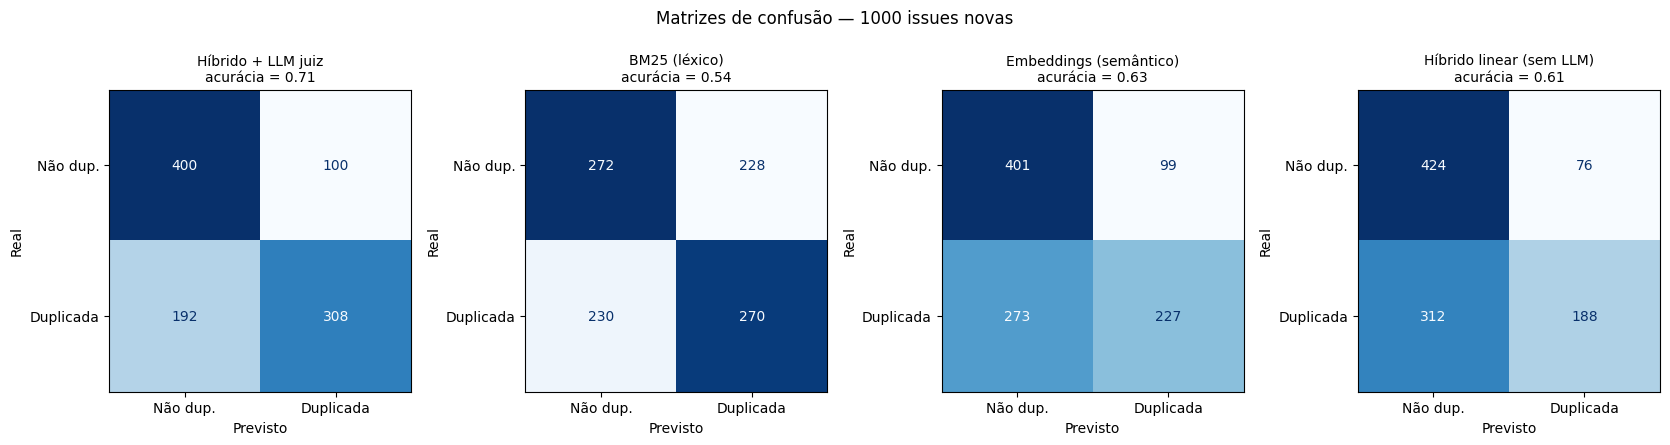

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score,
                             average_precision_score, precision_recall_fscore_support)

def aponta_certo(r):
    """True se a duplicata foi detectada E apontou para uma issue do cluster correto."""
    if pd.isna(r.duplicate_of):                      # não detectada (None vira NaN no DataFrame)
        return False
    k = [int(i) if str(i).isdigit() else i for i in r.cand_ids].index(int(r.duplicate_of))
    return r.cand_gt[k] == r.true_master

LLM_NOME = "Híbrido + LLM juiz"
# score contínuo + limiar de cada sistema (mesma régua para todos)
sist = {LLM_NOME: (res.score.values.astype(float), float(sistema.threshold))}
for n, nome in NOMES_BL.items():
    sist[nome] = (res[f"bl_{n}_score"].values.astype(float), LIMIARES_BL[n])

y = res.y_true.values
dup_mask = (y == 1)
link_llm = np.array([aponta_certo(r) for r in res.itertuples()])      # só vale para as duplicatas reais
rng_b = np.random.default_rng(SEED)
idx_b = rng_b.integers(0, len(y), size=(1000, len(y)))

linhas, cms = [], {}
for nome, (sc, thr) in sist.items():
    pred = res.pred.values if nome == LLM_NOME else (sc >= thr).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    p_, r_, f_, _ = precision_recall_fscore_support(y, pred, labels=[1], zero_division=0)
    if nome == LLM_NOME:
        link = link_llm[dup_mask].mean()
    else:
        n = [k for k, v in NOMES_BL.items() if v == nome][0]
        link = ((pred == 1) & (res[f"bl_{n}_gt"].values == res.true_master.values))[dup_mask].mean()
    acc_boot = np.array([(pred[i] == y[i]).mean() for i in idx_b])
    linhas.append({"Sistema": nome, "Limiar": round(thr, 3), "VP": tp_, "VN": tn_, "FP": fp_, "FN": fn_,
                   "Acurácia": (tp_ + tn_) / len(y),
                   "IC95% acc.": f"[{np.percentile(acc_boot, 2.5):.2f}, {np.percentile(acc_boot, 97.5):.2f}]",
                   "Precisão": p_[0], "Recall": r_[0], "F1 (dup.)": f_[0],
                   "AUC": roc_auc_score(y, sc), "AP": average_precision_score(y, sc),
                   "Aponta p/ original certa": link})
    cms[nome] = confusion_matrix(y, pred, labels=[0, 1])

tab = pd.DataFrame(linhas).set_index("Sistema")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(tab.drop(columns=["VP", "VN", "FP", "FN"]).round(3))        # contagens: nas matrizes e no CSV
tab.round(4).to_csv(f"{RUN_DIR}/comparacao_sistemas.csv")

fig, axes = plt.subplots(1, len(cms), figsize=(4.2 * len(cms), 4.2))
for ax, (nome, cm_) in zip(np.atleast_1d(axes), cms.items()):
    ConfusionMatrixDisplay(cm_, display_labels=["Não dup.", "Duplicada"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{nome}\nacurácia = {tab.loc[nome, 'Acurácia']:.2f}", fontsize=10)
    ax.set_xlabel("Previsto"); ax.set_ylabel("Real")
plt.suptitle(f"Matrizes de confusão — {len(res)} issues novas", y=1.02)
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/matrizes_confusao.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
# --- diagnóstico do pipeline com LLM: o erro vem da recuperação ou do juiz? ---
rel_llm = classification_report(y, res.pred.values, target_names=["Não duplicada", "Duplicada"], digits=3, output_dict=True)   # vai para o metricas.json
dups = res[res.y_true == 1]
def recall_em_k(col): return float(np.mean([m in g for m, g in zip(dups.true_master, dups[col])]))
rec_k = {"bm25": recall_em_k("bm25_gt"), "denso": recall_em_k("dense_gt"), "hibrido_rrf": recall_em_k("cand_gt")}
print("Recall@%d da recuperação (alguma candidata do cluster correto no top-%d):" % (TOP_K, TOP_K))
print(f"  BM25 {rec_k['bm25']:.0%} | Denso {rec_k['denso']:.0%} | Híbrido (RRF) {rec_k['hibrido_rrf']:.0%}")

print("\nDetecção das duplicatas pelo pipeline com LLM, conforme o local da original:")
det_local = {}
for loc, g in dups.groupby("orig_local"):
    det_local[loc] = {"detectadas": int(g.pred.sum()), "total": int(len(g))}
    print(f"  original na {loc:5s}: {int(g.pred.sum())}/{len(g)} detectadas ({g.pred.mean():.0%})")

Recall@5 da recuperação (alguma candidata do cluster correto no top-5):
  BM25 51% | Denso 63% | Híbrido (RRF) 63%

Detecção das duplicatas pelo pipeline com LLM, conforme o local da original:
  original na base : 172/250 detectadas (69%)
  original na teste: 136/250 detectadas (54%)


In [ ]:
# Erros do pipeline com LLM (FP = duplicata falsa, FN = duplicata perdida)
cols = ["id", "title", "y_true", "pred", "score", "duplicate_of", "true_master", "orig_local"]
fp_df = res[(res.y_true == 0) & (res.pred == 1)][cols]
fn_df = res[(res.y_true == 1) & (res.pred == 0)][cols]
print(f"Falsos positivos ({len(fp_df)}):"); display(fp_df)
print(f"Falsos negativos ({len(fn_df)}):"); display(fn_df)

pd.concat([fp_df.assign(tipo="FP"), fn_df.assign(tipo="FN")]).to_csv(f"{RUN_DIR}/erros_fp_fn.csv", index=False)
res.to_csv(f"{RUN_DIR}/resultados_avaliacao.csv", index=False)
sistema.salvar(f"{RUN_DIR}/base_total.csv")      # base final (1100 issues, com duplicate_of previsto nas novas)

Falsos positivos (100):


,id,title,y_true,pred,score,duplicate_of,true_master,orig_local
6,1726,Submit form keyboard shortcut doesnt work,0,1,1.000000,7081.0,1726,-
7,2743,Canvas is three pixels too wide for viewport; ...,0,1,0.692642,86837.0,2743,-
27,8322,Buttons have odd underline that extends outsid...,0,1,0.943348,7058.0,8322,-
30,9100,[bidi] Text direction ignored (dir; BDO; &lrm;...,0,1,1.000000,101339.0,9100,-
39,12513,HTMLSelectElement.options.selectedIndex not su...,0,1,1.000000,108673.0,12513,-
...,...,...,...,...,...,...,...,...
942,844112,GC: Fix misc build and test failures in exactl...,0,1,0.999993,828607.0,844112,-
961,887753,Server not found after reconnecting to etherpad,0,1,0.999999,470274.0,887753,-
987,935491,crash in EnterBaseline,0,1,0.999864,947773.0,935491,-
990,938107,Hang at shutdown since Firefox25,0,1,1.000000,452184.0,938107,-


Falsos negativos (192):


,id,title,y_true,pred,score,duplicate_of,true_master,orig_local
2,1015,navigator.mimeTypes not implemented,1,0,2.037748e-07,NaN,661,teste
8,2871,SPAN moved outside of H1,1,0,7.254362e-05,NaN,2825,base
13,4273,OnChange is not being fired in Select lists,1,0,4.539787e-05,NaN,3322,teste
16,5062,[PP]Apprunner crash on Win 95; Win NT and Win 98.,1,0,6.825603e-08,NaN,4703,base
20,6928,[BLOCKING WALLET] Deleting items in a SELECT l...,1,0,2.646574e-09,NaN,3187,teste
...,...,...,...,...,...,...,...,...
966,891458,crash in libskia.so@0x10affe,1,0,7.194133e-09,NaN,890590,teste
967,892104,Build race condition,1,0,8.777451e-11,NaN,850380,base
969,896052,missing check for isFloatAddress in MoveEmitte...,1,0,4.468087e-02,NaN,890271,teste
982,926589,[B2G][Contacts[Export] Black screen appears wh...,1,0,7.746073e-11,NaN,923303,teste


In [ ]:
def _py(o):
    """Converte tipos numpy para JSON."""
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)

CHAVES_CONFIG = ["SEED", "N_BASE", "N_EVAL", "FRAC_ORIG_TESTE", "EMB_MODEL", "LLM_MODEL", "TOP_K", "POOL", "RRF_K",
                 "ALPHA_HIB", "CALIBRAR", "N_CAL", "MAX_CHARS_EMB", "MAX_CHARS_LLM", "JUDGE_BS", "PROMPT_VERSION"]
metricas = {
    "execucao": time.strftime("%Y-%m-%d %H:%M:%S"),
    "config": {k: globals()[k] for k in CHAVES_CONFIG},
    "amostra": {
        "base": len(base_df), "base_duplicadas": int(base_df.is_duplicate.sum()),
        "teste": len(eval_df), "teste_duplicadas": int(eval_df.is_duplicate.sum()),
        "teste_duplicadas_por_local_da_original": eval_df[eval_df.is_duplicate == 1].orig_local.value_counts().to_dict(),
        "base_apos_simulacao": len(sistema.db),
    },
    "limiares": {"llm": float(sistema.threshold), **LIMIARES_BL},
    "acuracia_na_calibracao": {"llm": CAL_ACC_LLM, **CAL_ACC_BL},
    "sistemas": tab.reset_index().to_dict("records"),          # VP, VN, FP, FN, acurácia, IC95%, precisão, recall, F1, AUC, AP
    "relatorio_classificacao_llm": rel_llm,
    "recall_at_k_recuperacao": rec_k,
    "deteccao_llm_por_local_da_original": det_local,
    "tempo_simulacao_min": round(T_SIM_MIN, 2),
}
with open(f"{RUN_DIR}/metricas.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2, default=_py)

print("Resultados desta execução gravados em:", RUN_DIR)
for nome in sorted(os.listdir(RUN_DIR)):
    print(f"  {nome:28s} {os.path.getsize(os.path.join(RUN_DIR, nome)) / 1024:8.1f} KB")
print("Cache do juiz (compartilhado entre execuções):", CACHE_PATH)

Resultados desta execução gravados em: /content/drive/MyDrive/dedup_bugs/execucoes/20261119_123443
  amostra_1100.csv              11432.7 KB
  base_total.csv                 1231.7 KB
  comparacao_sistemas.csv           0.5 KB
  erros_fp_fn.csv                  30.4 KB
  matrizes_confusao.png            65.2 KB
  metricas.json                     3.5 KB
  resultados_avaliacao.csv        474.8 KB
Cache do juiz (compartilhado entre execuções): /content/drive/MyDrive/dedup_bugs/cache_juiz_Qwen3-8B_v1.jsonl


## 10. Usando o sistema como um tracker: submeter uma issue nova

In [ ]:
nova = {
    "Title": "Crash when resizing window while page is loading",
    "Component": "Layout",
    "Description": "Steps: open a large page, resize the browser window while it is still loading. Result: the browser crashes.",
}
r = sistema.submit(nova)
print("duplicata de:", r["duplicate_of"], "| score:", round(r["score"], 3), "| base agora tem", r["n_base"], "issues")
for cid, p in zip(r["cand_ids"], r["cand_p"]):
    print(f"  candidata {cid}: P(Yes)={p:.3f} -> {sistema.db[sistema.pos[cid]]['title'][:80]}")

duplicata de: None | score: 0.0 | base agora tem 11001 issues
  candidata 73262: P(Yes)=0.000 -> Crash on quitting while page is loading
  candidata 96591: P(Yes)=0.000 -> Page is not rendered correctly. After resizing the Window everything is fine.
  candidata 96600: P(Yes)=0.000 -> Page is not rendered correctly. After resizing the Window everything is fine.
  candidata 64410: P(Yes)=0.000 -> Closing a new window before the image is completely rendered causes a crash
  candidata 138977: P(Yes)=0.000 -> Mozilla crashes while loading new page when flash context menu is open
